# Assignment 3 - Fashion-MNIST Classification

In [14]:
from sklearn.model_selection import train_test_split
import tensorflow as tf
import pandas as pd

# Load Fashion-MNIST
(X_train, y_train), (X_test, y_test) = (
    tf.keras.datasets.fashion_mnist.load_data()
)

# Normalize pixel values to [0, 1]
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

# Flatten 28 x 28 images into 784 features
X_train = X_train.reshape(-1, 784)
X_test = X_test.reshape(-1, 784)

Starting with the starter code given by the teacher. This takes in the data Fashion-MNIST, normalizes the pixel values to [0, 1], and flattens 28x28 images into 784 features.

In [15]:
X_train, X_val, y_train, y_val = train_test_split(
    X_train, y_train, test_size=0.2, stratify=y_train, random_state=42
)

print(X_train.shape, X_val.shape, X_test.shape)

(48000, 784) (12000, 784) (10000, 784)


The 60,000 training images are split into a training set (80%, 48,000 images) and a validation set (20%, 12,000 images), using stratify so that all 10 classes are equally represented and a fixed random_state so the same split is used in every experiment. The models are trained on the training set and compared on the validation set, while the 10,000 test images are kept separate and used only once to evaluate the final selected model.

## Part A - Build and compare neural networks

### **Task 1. Build a baseline model with one hidden layer of 32 neurons using ReLU activation and the Adam optimizer. Train it and record its training and validation accuracy**

In [16]:
def build_model(neurons, activation, optimizer):
    tf.keras.utils.set_random_seed(42)
    model = tf.keras.Sequential([
        tf.keras.Input(shape=(784,)),
        tf.keras.layers.Dense(neurons, activation=activation),
        tf.keras.layers.Dense(10, activation="softmax")
    ])
    model.compile(optimizer=optimizer,
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])
    return model

build_model() creates the same kind of network as the Keras example in the lecture notes on slide 33, just with 784 inputs (one per pixel) instead of 64. Using one function means that all four models are built the same way, and only the setting we are testing changes. The random seed makes sure every model starts with the same initial weights.

* The hidden Dense layer calculates weighted sums plus a bias and applies an activation function, for example ReLU or tanh.
* The output layer has 10 neurons, one per clothing category, and softmax turns their scores into probabilities, explained in the lecture notes slide 15.
* compile() sets the loss using sparse categorical cross-entropy, which gives a big loss when the model gives a low probability to the right class. The optimizer updates the weights to minimize the loss using Adam or SGD.

-----------------------------------------------------------



fit() trains the model on the training set for 10 epochs (10 passes through the data) with a batch size of 64, so the weights are updated after every 64 images. As described in the lecture note slide 22, the model does a forward pass for each batch, calculates the loss, uses backpropagation to find the gradients, and then lets the optimizer update the weights. validation_data makes Keras check the accuracy on the validation set after each epoch, without training on it

In [17]:
baseline = build_model(32, "relu", "adam")
baseline.summary()

history_baseline = baseline.fit(X_train, y_train,
                                epochs=10, batch_size=64,
                                validation_data=(X_val, y_val))

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_8 (Dense)                 │ (None, 32)             │        25,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 25,450 (99.41 KB)

 Trainable params: 25,450 (99.41 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7907 - loss: 0.6260 - val_accuracy: 0.8356 - val_loss: 0.4745
Epoch 2/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8431 - loss: 0.4490 - val_accuracy: 0.8475 - val_loss: 0.4307
Epoch 3/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8572 - loss: 0.4095 - val_accuracy: 0.8564 - val_loss: 0.4068
Epoch 4/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8662 - loss: 0.3837 - val_accuracy: 0.8608 - val_loss: 0.3924
Epoch 5/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8717 - loss: 0.3662 - val_accuracy: 0.8658 - val_loss: 0.3830
Epoch 6/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8755 - loss: 0.3530 - val_accuracy: 0.8695 - val_loss: 0.3766
Epoch 7/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8796 - loss: 0.3422 - val_accuracy: 0.8704 - val_loss: 0.3703
Epoch 8/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8827 - loss: 0.3329 - val_accuracy: 0.

In [18]:
train_acc = history_baseline.history["accuracy"][-1]
val_acc = history_baseline.history["val_accuracy"][-1]
print(f"Baseline - train accuracy: {train_acc:.4f}, validation accuracy: {val_acc:.4f}")

Baseline - train accuracy: 0.8879, validation accuracy: 0.8733


The baseline model reached a training accuracy of 88.8% and a validation accuracy of 87.3%. Training accuracy shows how well the model does on the images it learns from, while validation accuracy shows how well it does on new images it has never trained on. Validation accuracy is therefore the most honest measure, and that's why it’s the one we are going to use to compare the models. The small gap between the two means the model isn’t overfitting much, so it hasn’t just memorized the training images.

### **Task 2. Starting from the baseline, run three more experiments. For each experiment, change only the setting shown below; keep the other settings the same as the baseline.**

Each experiment starts from the baseline (32 neurons, ReLU, Adam) and changes only one setting. Everything else stays the same. The same data split, 10 epochs, batch size 64, and the same random seed. That way, any difference in accuracy comes from the setting we changed. This is explained in lecture notes slide 32, compare fairly.

**Experiment 1:** 64 hidden neurons instead of 32.
More neurons give the model more capacity to learn patterns, but also more parameters to train. The question is whether this improves validation accuracy, or only training accuracy.

In [19]:
exp1 = build_model(64, "relu", "adam")
exp1.summary()

history_exp1 = exp1.fit(X_train, y_train, epochs=10, batch_size=64, validation_data=(X_val, y_val))

train_acc = history_exp1.history["accuracy"][-1]
val_acc = history_exp1.history["val_accuracy"][-1]
print(f"Experiment 1 - train accuracy: {train_acc:.4f}, validation accuracy: {val_acc:.4f}")

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_10 (Dense)                │ (None, 64)             │        50,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 50,890 (198.79 KB)

 Trainable params: 50,890 (198.79 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8005 - loss: 0.5802 - val_accuracy: 0.8400 - val_loss: 0.4679
Epoch 2/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8510 - loss: 0.4297 - val_accuracy: 0.8579 - val_loss: 0.4112
Epoch 3/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8632 - loss: 0.3896 - val_accuracy: 0.8698 - val_loss: 0.3782
Epoch 4/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8705 - loss: 0.3616 - val_accuracy: 0.8723 - val_loss: 0.3618
Epoch 5/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8768 - loss: 0.3411 - val_accuracy: 0.8729 - val_loss: 0.3541
Epoch 6/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8829 - loss: 0.3248 - val_accuracy: 0.8763 - val_loss: 0.3451
Epoch 7/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8877 - loss: 0.3110 - val_accuracy: 0.8758 - val_loss: 0.3467
Epoch 8/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8914 - loss: 0.2992 - val_accuracy: 0.

With 64 neurons, training accuracy went up from 88.8% to 89.9%, but validation accuracy only went up from 87.3% to 87.7%. The gap between training and validation also got a little bit bigger, so the extra capacity helped more on the training data than on new data.

**Experiment 2:** tanh instead of ReLU in the hidden layer.
Tanh is another nonlinear activation function, with outputs between −1 and 1, while ReLU sets negative values to 0 and keeps positive ones. ReLU is a common default, while tanh can saturate and make training slower, explained in slide 29.

In [20]:
exp2 = build_model(32, "tanh", "adam")

history_exp2 = exp2.fit(X_train, y_train, epochs=10, batch_size=64, validation_data=(X_val, y_val))

train_acc = history_exp2.history["accuracy"][-1]
val_acc = history_exp2.history["val_accuracy"][-1]
print(f"Experiment 2 - train accuracy: {train_acc:.4f}, validation accuracy: {val_acc:.4f}")

Epoch 1/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8011 - loss: 0.5969 - val_accuracy: 0.8411 - val_loss: 0.4409
Epoch 2/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8529 - loss: 0.4196 - val_accuracy: 0.8579 - val_loss: 0.3948
Epoch 3/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8643 - loss: 0.3819 - val_accuracy: 0.8635 - val_loss: 0.3754
Epoch 4/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8724 - loss: 0.3598 - val_accuracy: 0.8688 - val_loss: 0.3623
Epoch 5/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8769 - loss: 0.3441 - val_accuracy: 0.8732 - val_loss: 0.3531
Epoch 6/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8819 - loss: 0.3317 - val_accuracy: 0.8754 - val_loss: 0.3473
Epoch 7/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8850 - loss: 0.3214 - val_accuracy: 0.8776 - val_loss: 0.3434
Epoch 8/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8882 - loss: 0.3124 - val_accuracy: 0.

With tanh, validation accuracy was 88.1%, which is the highest of the four models, and the gap to training accuracy is the smallest of the Adam models. So in this case tanh worked slightly better than ReLU, even though ReLU is the usual default. The difference is small though, so the two activations perform roughly the same here.

**Experiment 3:** SGD instead of Adam.
Both optimizers use the gradients from backpropagation to update the weights. SGD takes simple steps with a fixed learning rate, while Adam adapts the step size using the gradient history, explained in slide 30.

In [21]:
exp3 = build_model(32, "relu", "sgd")

history_exp3 = exp3.fit(X_train, y_train, epochs=10, batch_size=64, validation_data=(X_val, y_val))

train_acc = history_exp3.history["accuracy"][-1]
val_acc = history_exp3.history["val_accuracy"][-1]
print(f"Experiment 3 - train accuracy: {train_acc:.4f}, validation accuracy: {val_acc:.4f}")

Epoch 1/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.6868 - loss: 0.9985 - val_accuracy: 0.7742 - val_loss: 0.6930
Epoch 2/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.7921 - loss: 0.6328 - val_accuracy: 0.8076 - val_loss: 0.5825
Epoch 3/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8136 - loss: 0.5605 - val_accuracy: 0.8192 - val_loss: 0.5345
Epoch 4/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8230 - loss: 0.5234 - val_accuracy: 0.8254 - val_loss: 0.5069
Epoch 5/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8297 - loss: 0.4999 - val_accuracy: 0.8300 - val_loss: 0.4884
Epoch 6/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8359 - loss: 0.4834 - val_accuracy: 0.8345 - val_loss: 0.4749
Epoch 7/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8394 - loss: 0.4708 - val_accuracy: 0.8374 - val_loss: 0.4647
Epoch 8/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8421 - loss: 0.4608 - val_accuracy: 0.

With SGD, both training and validation accuracy are clearly lower, 84.7% and 84.4%. The loss was still going down and the accuracy still going up in the last epochs, so the model hadn’t finished learning after 10 epochs. The small gap means this isn’t overfitting. The model just needs more training.

#### ***Task 3. Record the training and validation accuracy of all four models in a results table. Identify the model with the highest validation accuracy. Evaluate that model on the test set and report its test accuracy. Do not use the test set to choose the model.***

The table below shows the training and validation accuracy from the last epoch for all four models.

In [22]:
results = pd.DataFrame([
    ["Baseline",     32, "ReLU", "Adam", history_baseline.history["accuracy"][-1], history_baseline.history["val_accuracy"][-1]],
    ["Experiment 1", 64, "ReLU", "Adam", history_exp1.history["accuracy"][-1],     history_exp1.history["val_accuracy"][-1]],
    ["Experiment 2", 32, "tanh", "Adam", history_exp2.history["accuracy"][-1],     history_exp2.history["val_accuracy"][-1]],
    ["Experiment 3", 32, "ReLU", "SGD",  history_exp3.history["accuracy"][-1],     history_exp3.history["val_accuracy"][-1]],
], columns=["Model", "Hidden neurons", "Activation", "Optimizer", "Train accuracy", "Validation accuracy"])

results.round(4)

,Model,Hidden neurons,Activation,Optimizer,Train accuracy,Validation accuracy
0,Baseline,32,ReLU,Adam,0.8879,0.8733
1,Experiment 1,64,ReLU,Adam,0.8985,0.8774
2,Experiment 2,32,tanh,Adam,0.8933,0.8807
3,Experiment 3,32,ReLU,SGD,0.8470,0.8441


In [23]:
models = {"Baseline": baseline, "Experiment 1": exp1,
          "Experiment 2": exp2, "Experiment 3": exp3}

best_name = results.loc[results["Validation accuracy"].idxmax(), "Model"]
best_model = models[best_name]
print("Selected model:", best_name)

Selected model: Experiment 2


The selected model is experiment 2, using tanh. That's because this model had the highest validation accuracy, at 88.1%. Until now, we have only used the training and validation data, the test data has stayed untouched. We are now going to use the test data to evaluate the selected model

In [24]:
test_loss, test_acc = best_model.evaluate(X_test, y_test, verbose=0)

print(f"Selected model: {best_name}")
print(f"Validation accuracy: {results['Validation accuracy'].max():.4f}")
print(f"Test accuracy:       {test_acc:.4f}")

Selected model: Experiment 2
Validation accuracy: 0.8807
Test accuracy:       0.8661


The selected model, experiment 2 using tanh, reached a test accuracy of 86.6%, which is a bit lower than its validation accuracy of 88.1%. We picked the model that did best on the validation set, so its validation accuracy is slightly optimistic. The test accuracy is the most honest estimate of how well the model works on completely new images.

## **Part B - Explain your neural network**

**Q1. Architecture and parameters.**

Weights:

* Input to hidden layer: 784 × 32 = 25,088
* Hidden to output: 32 × 10 = 320
* Total weights: 25,408

Biases (one per neuron): 32 + 10 = 42

We are training both the weights and the biases, so total trainable parameters are: 25,408 + 42 = 25,450, which matches baseline.summary() in task 1 part A.

This is explained in slide 31. A parameter is something the model learns during training, like the weights and biases. They’re updated by the optimizer using the gradients. A hyperparameter is a setting we choose before training, like the number of neurons, the activation function, the optimizer, the number of epochs and the batch size. The hyperparameters are what we changed and tested in task 2.

**Q2. Activation and loss**

As described in lecture notes slide 29, ReLU keeps positive values and sets negative ones to 0, and is therefore simple and fast. ReLU is used because it’s nonlinear, which lets the network learn more complex patterns. Without it, adding more layers would still only give a linear model (slide 9). Softmax turns the 10 output scores into probabilities that add up to 1, and the class with the highest probability is the prediction.

Sparse categorical cross-entropy fits because there are 10 classes and the labels are integers (0–9). It gives a big loss when the model gives a low probability to the correct class, which is visualized in the graph in slide 19.

**Q3. Training and Keras functions**

* As already explained in part A, compile() sets up how the model learns: the loss function, the optimizer and the metric (accuracy).
* fit() trains the model. For each batch it does a forward pass, calculates the loss and updates the weights, and it repeats this for all epochs.
* evaluate() measures loss and accuracy on data the model hasn’t trained on, like the test set, without changing the weights.
* predict() returns the 10 softmax probabilities for each image, and the class with the highest one is the prediction.

Backpropagation (explained in slide 22) works backwards from the loss and calculates the gradient for each weight, which means how much the loss changes if that weight changes a little. The optimizer then uses these gradients to update the weights so that the loss gets smaller.

**Q4. Interpreting the experiments**

Experiment 2 using tanh had the highest validation accuracy at 88.1%, compared to 87.3% for the baseline model.

* 64 neurons raised training accuracy more than validation accuracy (89.9% vs 87.7%), so the extra capacity mostly helped on the training data
* Tanh gave a small improvement, but the difference from ReLU is just 1% points, so they performed about the same.
* SGD made the results clearly worse, with 84.4% validation. The loss was still decreasing after 10 epochs, so SGD learns more slowly than Adam and needs more training. Maybe changing the default learning rate could have helped.

What we see is that more neurons or a different setting doesn’t automatically mean a better model. That’s why we tested just one setting at a time, and then tested on the validation set which is separated from the training data.

## **Part C — Understand classification errors**

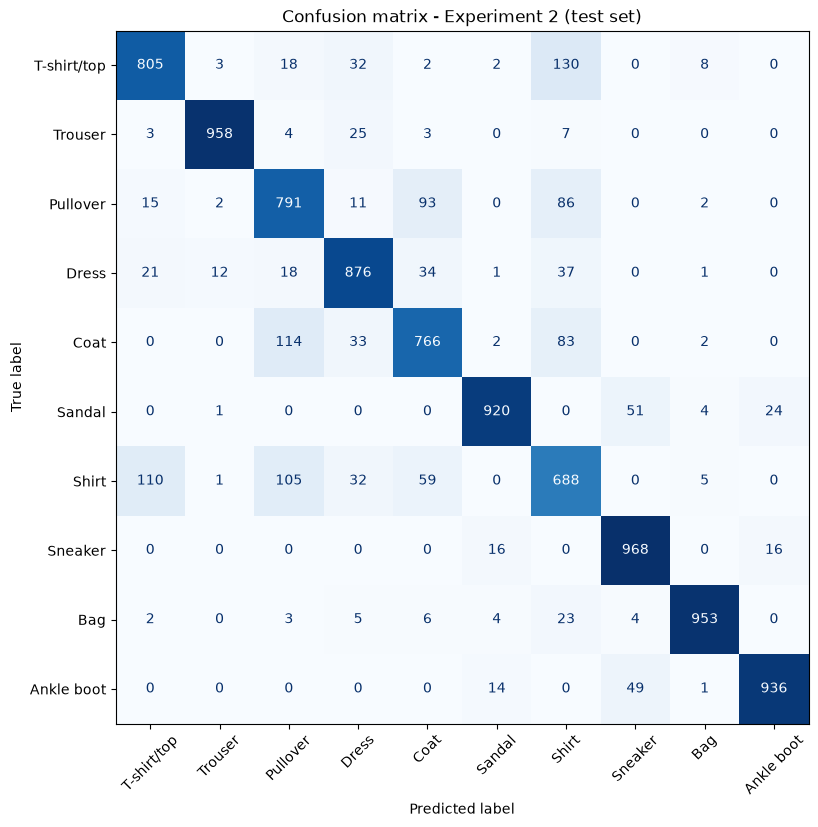

In [25]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

probabilities = best_model.predict(X_test, verbose=0)
y_pred = np.argmax(probabilities, axis=1)

cm = confusion_matrix(y_test, y_pred)

fig, ax = plt.subplots(figsize=(9, 9))
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(
    ax=ax, cmap="Blues", xticks_rotation=45, colorbar=False)
ax.set_title(f"Confusion matrix - {best_name} (test set)")
plt.show()